# Plasma Potential Analysis
## Recreating figure 1 from NASA paper

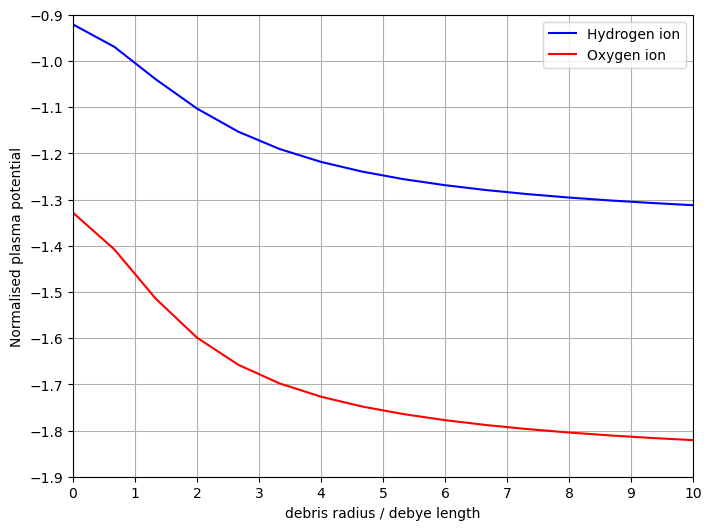

In [4]:
from scipy.optimize import brentq
import numpy as np
import matplotlib.pyplot as plt

def surface_potential_equation(x, mass_ratio, s, a):
    """Equation 32 from the NASA paper in the form 0 = f(x) where f(x) is equal to g(x) - A(1-B * e(Cx), this equation is then put through brents method to identify the roots of the function """
    return np.exp(x) - np.sqrt(mass_ratio) * ((s/a)**2) * ( 1 - ((s**2 - a**2)/s**2) * np.exp( (a**2 / (s**2 - a**2)) * x ))

#consants
__me__ = 9.1093837139e-31 # Electron mass in kg
__mh__ = 1.67262192595e-27 # Hydrogen ion aka proton mass in kg
__mo__ = 15.994914619 * 1.66053906892e-27 # Oxygen ion mass in kg
debye_length = 1 # Example value for debye radius

r = debye_length # Distance from the debris surface the potnetial is felt too, which for plasma is the debye length, this is used to normalise the plasma potential

a_array = np.linspace( 1e-3, 10, 16) # Array of debris radii from 0.00001 to 10 in 16 steps

phi_ox= np.zeros(len(a_array))
phi_h = np.zeros(len(a_array))

# Calculate the normalised plasma potential for each debris radius
for i, a in enumerate(a_array):
    mass_ratio = __me__ / __mo__
    s = a + debye_length
    x_solution = brentq(surface_potential_equation, -20, 0, args=(mass_ratio, s, a))
    phi_ox[i] = x_solution * np.exp(-r/ debye_length)  # normalised plasma potential

for i, a in enumerate(a_array):
    mass_ratio = __me__ / __mh__
    s = a + debye_length
    x_solution = brentq(surface_potential_equation, -20, 0, args=(mass_ratio, s, a))
    phi_h[i] = x_solution * np.exp(-r/ debye_length)  # normalised plasma potential

# PLOTTING
plt.figure(figsize=(8, 6))
plt.grid()
plt.plot(a_array / debye_length, phi_h, label="Hydrogen ion", color="blue")
plt.plot(a_array/ debye_length, phi_ox, label="Oxygen ion", color="red")
plt.xlabel("debris radius / debye length")
plt.ylabel("Normalised plasma potential")
plt.xticks(np.arange(0, 11, 1))
plt.yticks(np.arange(-2, 1, 0.1))
plt.xlim(0, 10)
plt.ylim( -1.9,-0.9)
plt.legend()
plt.show()

### Functionisng the Normalised Plasma Potential Calculation & Validating against NASA paper values (Table 6)

In [5]:
from scipy.optimize import brentq
import numpy as np

def normalised_plasma_potential(a, debye_length, mass_ratio, potential_radius = None):
    """Calculates the normalised plasma potential for a given debris radius, debye length, and mass ratio."""
    def eqn_surface_potential(x, mass_ratio, s, a):
        """Equation 32 from the NASA paper in the form 0 = f(x) where f(x) is equal to g(x) - A(1-B * e(Cx), this equation is then put through brents method to identify the roots of the function, eφ/kT"""
        return np.exp(x) - np.sqrt(mass_ratio) * (s/a)**2  * ( 1 - ((s**2 - a**2)/s**2) * np.exp( (a**2 / (s**2 - a**2)) * x ))

    # If potential_radius is not provided, it defaults to the debye_length.
    if potential_radius is None:
        potential_radius = debye_length

    s = a + debye_length

    x_sol = brentq(eqn_surface_potential, -10, 0, args=(mass_ratio, s, a))
    phi_np = x_sol * np.exp(-potential_radius/debye_length)  # normalised plasma potential

    return phi_np

# ========= Validation against NASA paper values (Table 6) =========
__me__ = 9.1093837139e-31 # Electron mass in kg
__mh__ = 1.67262192595e-27 # Hydrogen ion aka proton mass in kg
__mo__ = 15.994914619 * 1.66053906892e-27 # Oxygen ion mass in kg

mass_ratio_o = __me__ / __mo__
mass_ratio_h = __me__ / __mh__

# values extracted from NASA paper Table 6 f

debris_diameters= [10e-2, 5e-2, 1e-2, 5e-3, 1e-3] # Debris diameters in meters
debye_lengths = [.83e-2, 1.38e-2, 4.36e-2, 23504e-2] # Debye lengths for Low LEO, Low LEO I, Low LEO II, and GEO respectively in meters

lowleo_phi_values = [-1.77, -1.68, -1.40, -1.35, -1.33]
lowleoi_phi_values = [-1.20, -1.08, -0.94, -0.93, -0.92]
lowleoii_phi_values = [-1.02, -0.96, -0.92, -0.92, -0.92]

debris_radii = [d/2 for d in debris_diameters] # Debris radii in meters

# Low LEO
print("=Normalised plasma potential calculations for Low LEO region (Oxygen)=:")
for a in debris_radii:
    phi_lowleo = normalised_plasma_potential(a, debye_lengths[0], mass_ratio_o)
    uncertainty = abs(phi_lowleo - lowleo_phi_values[debris_radii.index(a)])
    print(f"Debris radius: {a:.1e} m, Normalised plasma potential: {phi_lowleo:.3f}, uncertainty: {uncertainty:.3f}")

# Low LEO I
print("\n=Normalised plasma potential calculations for Low LEO I region (Hydrogen)=:")
for a in debris_radii:
    phi_lowleoi = normalised_plasma_potential(a, debye_lengths[1], mass_ratio_h)
    uncertainty = abs(phi_lowleoi - lowleoi_phi_values[debris_radii.index(a)])
    print(f"Debris radius: {a:.1e} m, Normalised plasma potential: {phi_lowleoi:.3f}, uncertainty: {uncertainty:.3f}")

# Low LEO
print("=Normalised plasma potential calculations for Low LEO region (Oxygen)=:")
for a in debris_radii:
    phi_lowleo = normalised_plasma_potential(a, debye_lengths[0], mass_ratio_o)
    uncertainty = abs(phi_lowleo - lowleo_phi_values[debris_radii.index(a)])
    print(f"Debris radius: {a:.1e} m, Normalised plasma potential: {phi_lowleo:.3f}, uncertainty: {uncertainty:.3f}")

# Low LEO I
print("\n=Normalised plasma potential calculations for Low LEO I region (Hydrogen)=:")
for a in debris_radii:
    phi_lowleoi = normalised_plasma_potential(a, debye_lengths[1], mass_ratio_h)
    uncertainty = abs(phi_lowleoi - lowleoi_phi_values[debris_radii.index(a)])
    print(f"Debris radius: {a:.1e} m, Normalised plasma potential: {phi_lowleoi:.3f}, uncertainty: {uncertainty:.3f}")

# Low LEO II
print("\n=Normalised plasma potential calculations for Low LEO II region (Hydrogen)=:")
for a in debris_radii:
    phi_lowleoii = normalised_plasma_potential(a, debye_lengths[2], mass_ratio_h)
    uncertainty = abs(phi_lowleoii - lowleoii_phi_values[debris_radii.index(a)])
    print(f"Debris radius: {a:.1e} m, Normalised plasma potential: {phi_lowleoii:.3f}, uncertainty: {uncertainty:.3f}")

=Normalised plasma potential calculations for Low LEO region (Oxygen)=:
Debris radius: 5.0e-02 m, Normalised plasma potential: -1.778, uncertainty: 0.008
Debris radius: 2.5e-02 m, Normalised plasma potential: -1.680, uncertainty: 0.000
Debris radius: 5.0e-03 m, Normalised plasma potential: -1.398, uncertainty: 0.002
Debris radius: 2.5e-03 m, Normalised plasma potential: -1.353, uncertainty: 0.003
Debris radius: 5.0e-04 m, Normalised plasma potential: -1.330, uncertainty: 0.000

=Normalised plasma potential calculations for Low LEO I region (Hydrogen)=:
Debris radius: 5.0e-02 m, Normalised plasma potential: -1.204, uncertainty: 0.004
Debris radius: 2.5e-02 m, Normalised plasma potential: -1.086, uncertainty: 0.006
Debris radius: 5.0e-03 m, Normalised plasma potential: -0.941, uncertainty: 0.001
Debris radius: 2.5e-03 m, Normalised plasma potential: -0.927, uncertainty: 0.003
Debris radius: 5.0e-04 m, Normalised plasma potential: -0.921, uncertainty: 0.001
=Normalised plasma potential ca

calculating forcing term in low leo

Plotting.


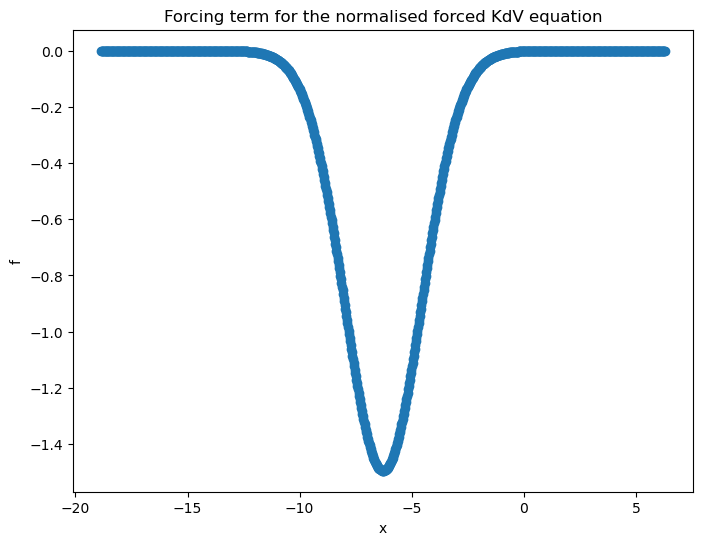

In [7]:

from scipy.optimize import brentq
import numpy as np
import matplotlib.pyplot as plt

def forcing_term(np_potential, xi, tau, vd, G):
    return np_potential * np.exp(-1 * ((e - (vd * tau)) / G) ** 2)


a = 0.01  # Debris radius in m
L = 2 * np.pi  # size of the domain
vd = 0
N = 1024

tau = np.linspace(0, L, N)
xi = np.linspace(-3 * L, L, N)

e = (np.pi / L) * (xi + L)

debye_length = .83e-2
__me__ = 9.1093837139e-31  # Electron mass in kg
__mh__ = 1.67262192595e-27  # Hydrogen ion aka proton mass in kg
__mo__ = 15.994914619 * 1.66053906892e-27  # Oxygen ion mass in kg
mass_ratio_o = __me__ / __mo__

G = a / debye_length  # Normalised forcing width
np_potential = normalised_plasma_potential(a, debye_length, mass_ratio_o)

print("Plotting.")

# 3D surface plot

f = forcing_term(np_potential, xi, 1, vd, G)

plt.figure(figsize=(8, 6))
plt.scatter(xi, f)
plt.xlabel('x')
plt.ylabel('f')
plt.title('Forcing term for the normalised forced KdV equation')
plt.show()